# Load the image and create a binary mask

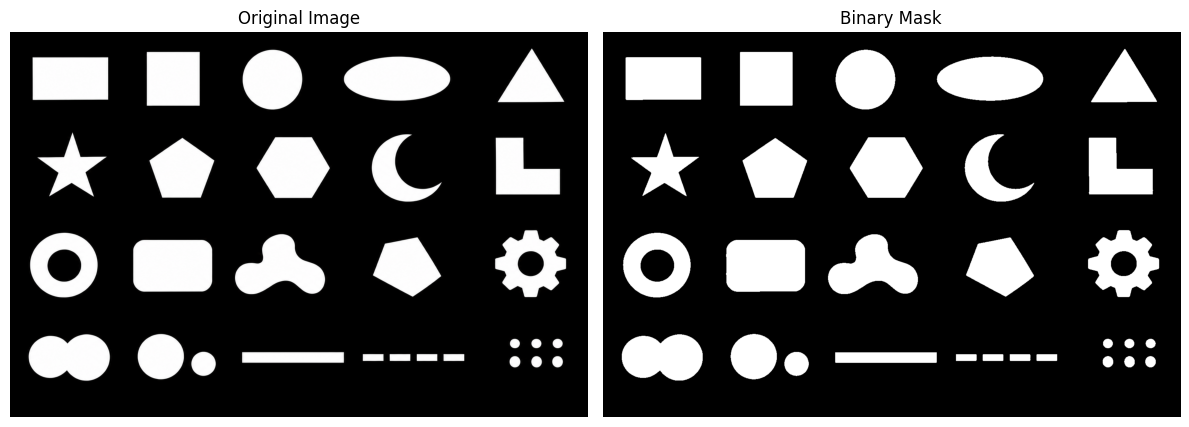

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = "images/05_image.png"

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

blurred = cv2.GaussianBlur(gray, (5, 5), 0)

_, binary = cv2.threshold(
    blurred, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Image")

axes[1].imshow(binary, cmap="gray")
axes[1].set_title("Binary Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Contour detection

## OpenCV Contour Detection — Short Notes

```python
contours, hierarchy = cv2.findContours(
    binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)
```

- **`binary.copy()`**: Processes a copy of the binary image, preserving the original array.
- **`cv2.RETR_EXTERNAL`**: Retrieves only the outermost contours, ignoring inner boundaries such as holes.
- **`cv2.CHAIN_APPROX_SIMPLE`**: Compresses contour points by removing redundant points along straight segments.
- **`contours`**: List of detected contours, each containing boundary coordinates.
- **`hierarchy`**: Stores contour relationships as `[next, previous, first_child, parent]`.

### Other Retrieval Modes
- `RETR_LIST`: Retrieves all contours without parent-child relationships.
- `RETR_TREE`: Retrieves all contours with full hierarchy.
- `RETR_CCOMP`: Organizes contours into a two-level hierarchy.

**Remember:** `RETR_*` controls which contours are retrieved; `CHAIN_APPROX_*` controls how contour points are stored.

Number of contours: 29


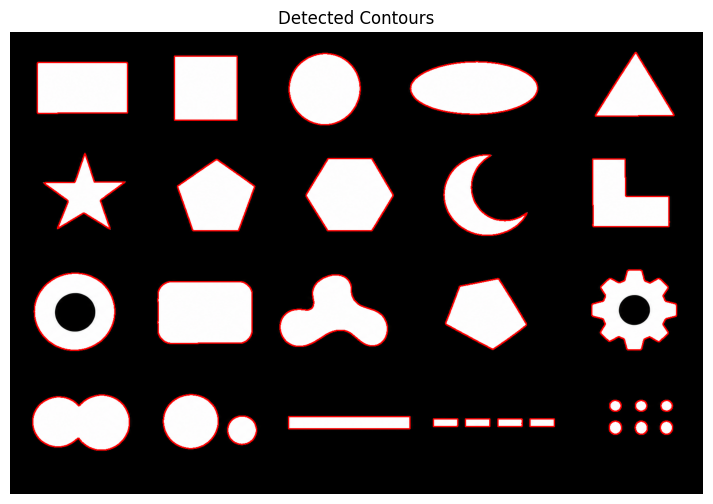

In [2]:
contours, hierarchy = cv2.findContours(
    binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# hierarchy --> [next, previous, first_child, parent]
# Each contour contains a sequence of boundary coordinates.
# You can access an individual contour using contours[0], contours[1], and so on.

print("Number of contours:", len(contours))

contour_image = image_rgb.copy()

cv2.drawContours(
    contour_image,
    contours,
    contourIdx=-1,
    color=(255, 0, 0),
    thickness=2
)

plt.figure(figsize=(9, 6))
plt.imshow(contour_image)
plt.title("Detected Contours")
plt.axis("off")
plt.show()

# Bounding boxes

## Axis-aligned bounding boxes

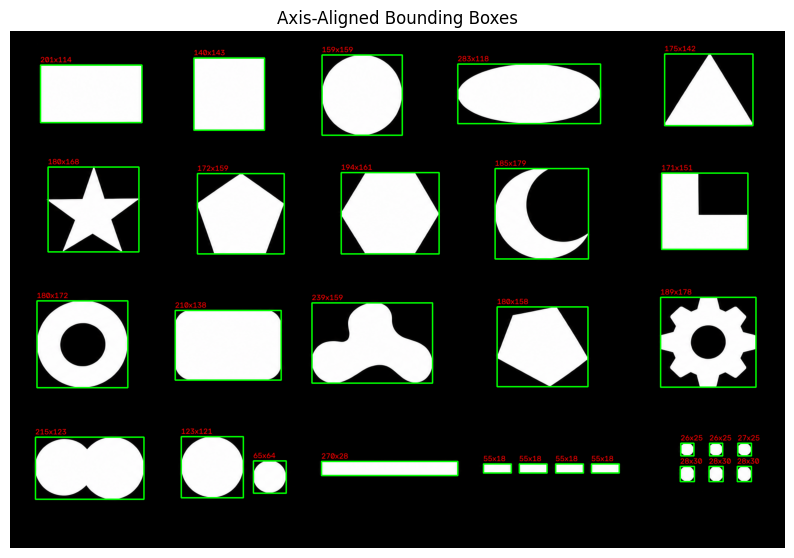

In [3]:
bbox_image = image_rgb.copy()

for contour in contours:
    if cv2.contourArea(contour) < 100:
        continue

    x, y, w, h = cv2.boundingRect(contour)

    cv2.rectangle(
        bbox_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        bbox_image,
        f"{w}x{h}",
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(10, 7))
plt.imshow(bbox_image)
plt.title("Axis-Aligned Bounding Boxes")
plt.axis("off")
plt.show()

# Rotated bounding boxes

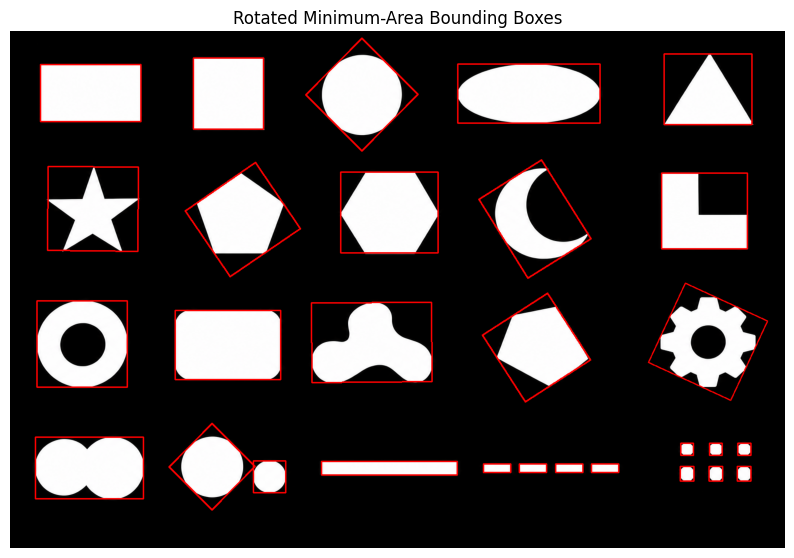

In [4]:
rotated_image = image_rgb.copy()

for contour in contours:
    if cv2.contourArea(contour) < 100:
        continue

    rect = cv2.minAreaRect(contour)
    box = cv2.boxPoints(rect)
    box = np.int32(box)

    cv2.drawContours(
        rotated_image,
        [box],
        -1,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(10, 7))
plt.imshow(rotated_image)
plt.title("Rotated Minimum-Area Bounding Boxes")
plt.axis("off")
plt.show()

# Convex hull

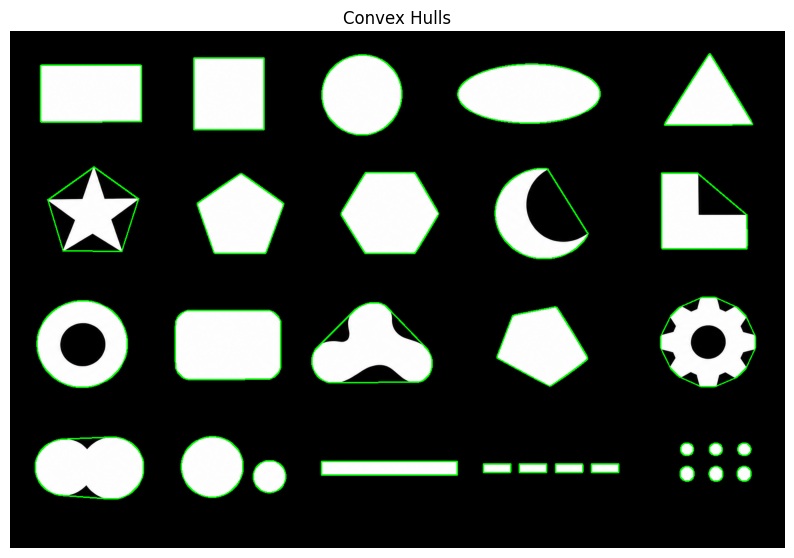

In [5]:
hull_image = image_rgb.copy()

for contour in contours:
    if cv2.contourArea(contour) < 100:
        continue

    hull = cv2.convexHull(contour)

    cv2.drawContours(
        hull_image,
        [hull],
        -1,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(10, 7))
plt.imshow(hull_image)
plt.title("Convex Hulls")
plt.axis("off")
plt.show()

# Image moments

In [ ]:
# Moment	Meaning for a contour
# m00	    Contour area
# m10	    Horizontal position accumulated over the contour's area
# m01	    Vertical position accumulated over the contour's area
# cx	    Horizontal coordinate of the centroid
# cy	    Vertical coordinate of the centroid

In [6]:
for index, contour in enumerate(contours):
    area = cv2.contourArea(contour)

    if area < 100:
        continue

    moments = cv2.moments(contour)

    if moments["m00"] == 0:
        continue

    cx = int(moments["m10"] / moments["m00"])
    cy = int(moments["m01"] / moments["m00"])

    print(f"Contour {index}")
    print(f"Area: {area:.2f}")
    print(f"Centroid: ({cx}, {cy})")

Contour 0
Area: 628.00
Centroid: (1454, 876)
Contour 1
Area: 621.50
Centroid: (1398, 876)
Contour 2
Area: 630.00
Centroid: (1341, 876)
Contour 3
Area: 916.50
Centroid: (1179, 865)
Contour 4
Area: 913.50
Centroid: (1107, 865)
Contour 5
Area: 916.00
Centroid: (1036, 865)
Contour 6
Area: 916.00
Centroid: (964, 865)
Contour 7
Area: 7262.00
Centroid: (751, 865)
Contour 8
Area: 3165.00
Centroid: (513, 882)
Contour 9
Area: 484.50
Centroid: (1454, 828)
Contour 10
Area: 481.00
Centroid: (1398, 828)
Contour 11
Area: 483.50
Centroid: (1341, 828)
Contour 12
Area: 20759.00
Centroid: (159, 864)
Contour 13
Area: 11439.50
Centroid: (400, 862)
Contour 14
Area: 27686.00
Centroid: (431, 621)
Contour 15
Area: 17692.50
Centroid: (1053, 623)
Contour 16
Area: 21542.50
Centroid: (716, 629)
Contour 17
Area: 24002.50
Centroid: (142, 619)
Contour 18
Area: 21212.00
Centroid: (1383, 615)
Contour 19
Area: 18616.00
Centroid: (456, 368)
Contour 20
Area: 17300.00
Centroid: (1358, 371)
Contour 21
Area: 23364.50
Centroi

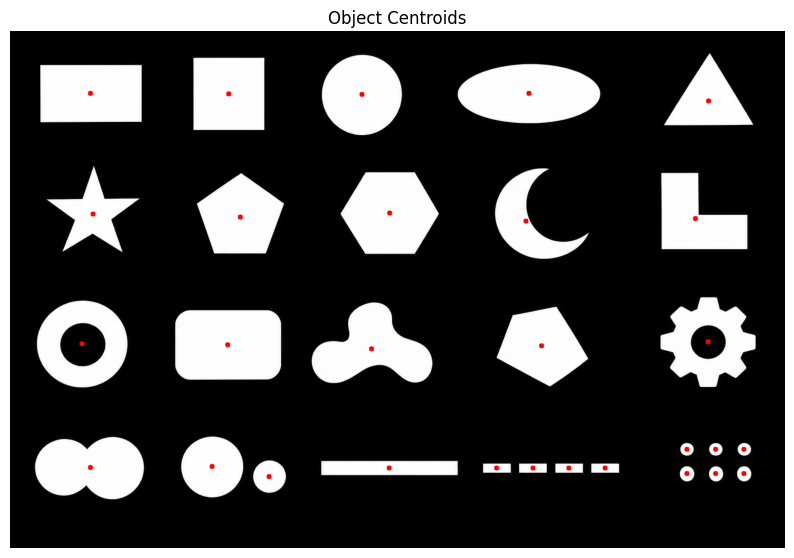

In [7]:
centroid_image = image_rgb.copy()

for contour in contours:
    if cv2.contourArea(contour) < 100:
        continue

    moments = cv2.moments(contour)

    if moments["m00"] == 0:
        continue

    cx = int(moments["m10"] / moments["m00"])
    cy = int(moments["m01"] / moments["m00"])

    cv2.circle(
        centroid_image,
        (cx, cy),
        5,
        (255, 0, 0),
        -1
    )

plt.figure(figsize=(10, 7))
plt.imshow(centroid_image)
plt.title("Object Centroids")
plt.axis("off")
plt.show()

# Shape measurements

In [8]:
measurements = []

for index, contour in enumerate(contours):
    area = cv2.contourArea(contour)

    if area < 100:
        continue

    perimeter = cv2.arcLength(contour, True)

    x, y, w, h = cv2.boundingRect(contour)

    aspect_ratio = w / h if h > 0 else 0

    bounding_box_area = w * h
    extent = area / bounding_box_area if bounding_box_area > 0 else 0

    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)

    solidity = area / hull_area if hull_area > 0 else 0

    circularity = (
        4 * np.pi * area / (perimeter ** 2)
        if perimeter > 0 else 0
    )

    measurements.append({
        "contour_id": index,
        "area_px2": round(area, 2),
        "perimeter_px": round(perimeter, 2),
        "width_px": w,
        "height_px": h,
        "aspect_ratio": round(aspect_ratio, 3),
        "extent": round(extent, 3),
        "solidity": round(solidity, 3),
        "circularity": round(circularity, 3)
    })

for item in measurements:
    print(item)

{'contour_id': 0, 'area_px2': 628.0, 'perimeter_px': 93.25, 'width_px': 28, 'height_px': 30, 'aspect_ratio': 0.933, 'extent': 0.748, 'solidity': 0.984, 'circularity': 0.907}
{'contour_id': 1, 'area_px2': 621.5, 'perimeter_px': 93.84, 'width_px': 28, 'height_px': 30, 'aspect_ratio': 0.933, 'extent': 0.74, 'solidity': 0.979, 'circularity': 0.887}
{'contour_id': 2, 'area_px2': 630.0, 'perimeter_px': 93.25, 'width_px': 28, 'height_px': 30, 'aspect_ratio': 0.933, 'extent': 0.75, 'solidity': 0.985, 'circularity': 0.91}
{'contour_id': 3, 'area_px2': 916.5, 'perimeter_px': 140.24, 'width_px': 55, 'height_px': 18, 'aspect_ratio': 3.056, 'extent': 0.926, 'solidity': 1.0, 'circularity': 0.586}
{'contour_id': 4, 'area_px2': 913.5, 'perimeter_px': 141.07, 'width_px': 55, 'height_px': 18, 'aspect_ratio': 3.056, 'extent': 0.923, 'solidity': 0.998, 'circularity': 0.577}
{'contour_id': 5, 'area_px2': 916.0, 'perimeter_px': 139.66, 'width_px': 55, 'height_px': 18, 'aspect_ratio': 3.056, 'extent': 0.925,

# OpenCV Notes: Contours

## 4.1 Contour Detection

### 1. What is a contour?

A **contour is a curve joining the boundary points of an object** having the same intensity or color.

In OpenCV, contours are commonly detected from binary images, where the foreground object is white and the background is black.

**Example:** If a white circle appears on a black background, its contour represents the circle's boundary.

### 2. Why do we use contours?

- Detect and separate objects.
- Find object boundaries.
- Calculate area and perimeter.
- Locate objects using bounding boxes.
- Analyze shapes and their geometric properties.
- Build applications such as object counting, document analysis, and industrial inspection.

### 3. Contour detection workflow

1. Read the image.
2. Convert it to grayscale.
3. Apply thresholding or edge detection to obtain a suitable binary image.
4. Detect contours using `cv2.findContours()`.
5. Filter unwanted contours.
6. Analyze or draw the detected contours.

### 4. Important functions

**Detect contours**

```python
contours, hierarchy = cv2.findContours(
    binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)
```

- `binary.copy()` — supplies the binary image without risking changes to the original array.
- `cv2.RETR_EXTERNAL` — retrieves only the outermost contours.
- `cv2.CHAIN_APPROX_SIMPLE` — compresses redundant contour points along straight segments.
- `contours` — list of detected contours.
- `hierarchy` — describes relationships between contours.

**Draw contours**

```python
cv2.drawContours(
    image,
    contours,
    contourIdx=-1,
    color=(0, 255, 0),
    thickness=2
)
```

- `contourIdx=-1` — draws all contours.
- `contourIdx=0` — draws the first contour.
- `thickness=2` — draws boundaries with a thickness of two pixels.

### 5. Contour retrieval modes

| Mode | Purpose |
|---|---|
| `RETR_EXTERNAL` | Retrieves outermost contours only |
| `RETR_LIST` | Retrieves all contours without parent-child hierarchy |
| `RETR_TREE` | Retrieves contours with full hierarchy |
| `RETR_CCOMP` | Organizes contours into a two-level hierarchy |

**When to use:** Use `RETR_EXTERNAL` for independent outer object boundaries. Use `RETR_TREE` when nested boundaries and holes matter.

### 6. Contour approximation methods

- `CHAIN_APPROX_NONE` — stores all contour boundary points.
- `CHAIN_APPROX_SIMPLE` — removes redundant points along straight segments.

For example, a rectangular contour may need only four corner points with `CHAIN_APPROX_SIMPLE`, instead of storing every boundary pixel.

---

## 4.2 Bounding Boxes

### 1. What is a bounding box?

A **bounding box is the smallest upright rectangle that completely encloses an object**.

It helps identify an object's location and approximate dimensions.

### 2. Axis-aligned bounding box

An axis-aligned bounding box has sides parallel to the image's horizontal and vertical axes.

```python
x, y, w, h = cv2.boundingRect(contour)
```

- `x` — x-coordinate of the top-left corner.
- `y` — y-coordinate of the top-left corner.
- `w` — width of the bounding box.
- `h` — height of the bounding box.

### 3. Draw a bounding box

```python
x, y, w, h = cv2.boundingRect(contour)

cv2.rectangle(
    image,
    (x, y),
    (x + w, y + h),
    (0, 255, 0),
    2
)
```

The rectangle encloses the contour. OpenCV's rectangle endpoints are inclusive, so the drawn edge can extend to the coordinate `(x + w, y + h)`.

### 4. Rotated bounding box

For an object tilted relative to the image axes, use a rotated rectangle.

```python
rect = cv2.minAreaRect(contour)
box = cv2.boxPoints(rect)
box = box.astype("int32")

cv2.drawContours(image, [box], 0, (0, 0, 255), 2)
```

- `cv2.minAreaRect()` — finds a minimum-area rotated rectangle enclosing the contour.
- `cv2.boxPoints()` — returns its four corner coordinates.

### 5. Applications

- Object detection and localization.
- Measuring approximate width and height.
- Cropping regions of interest.
- Detecting objects on production lines.
- Preprocessing images for classification.

**Limitation:** Two different shapes can have identical bounding boxes. A bounding box describes the object's extent, not its exact geometry.

---

## 4.3 Convex Hull

### 1. What is a convex hull?

A **convex hull is the smallest convex boundary enclosing all points of a shape**.

Imagine stretching a rubber band around an object's outermost points. The stretched band approximates its convex hull.

A convex shape has no inward dents. The convex hull bridges those dents.

### 2. Convex hull in OpenCV

```python
hull = cv2.convexHull(contour)

cv2.drawContours(
    image,
    [hull],
    -1,
    (0, 0, 255),
    2
)
```

- `contour` — original boundary points.
- `cv2.convexHull()` — computes the convex hull.
- `hull` — points describing the enclosing convex boundary.

### 3. Contour versus convex hull

| Contour | Convex hull |
|---|---|
| Follows the actual detected boundary | Encloses the contour with a convex boundary |
| Preserves inward dents | Bridges inward dents |
| Can be concave | Is convex |
| Used for actual boundary measurements | Useful for shape comparison and defect analysis |

### 4. Solidity

Solidity measures how much of the convex hull is occupied by the contour.

\[
\text{Solidity} =
\frac{\text{Contour Area}}{\text{Convex Hull Area}}
\]

```python
area = cv2.contourArea(contour)
hull = cv2.convexHull(contour)
hull_area = cv2.contourArea(hull)

solidity = area / hull_area if hull_area > 0 else 0
```

A value near 1 indicates that the contour fills most of its convex hull. More pronounced inward dents generally reduce solidity.

### 5. Applications

- Detecting defects in manufactured components.
- Comparing object shapes.
- Identifying concave regions.
- Hand gesture and silhouette analysis.

---

## 4.4 Image Moments

### 1. What are image moments?

**Image moments are numerical measurements describing the distribution of a shape's area or pixel intensities.**

They help calculate the centroid and describe how a shape is distributed in an image.

Think of a shape as a flat object with uniform density. Moments help locate its balance point.

### 2. Calculate moments

```python
moments = cv2.moments(contour)
```

The returned dictionary contains moments such as `m00`, `m10`, and `m01`.

### 3. Important moments

| Moment | Meaning |
|---|---|
| `m00` | Area of the contour when moments are calculated from a contour |
| `m10` | First spatial moment in the horizontal direction |
| `m01` | First spatial moment in the vertical direction |

For a binary image, `cv2.moments(binary_image, binaryImage=True)` calculates moments from foreground pixels instead. In that case, `m00` is the number of foreground pixels.

### 4. Centroid calculation

The centroid is the geometric center calculated from the shape's area distribution.

\[
C_x = \frac{M_{10}}{M_{00}}
\]

\[
C_y = \frac{M_{01}}{M_{00}}
\]

- `Cx` — horizontal coordinate.
- `Cy` — vertical coordinate.

### 5. Implementation

```python
moments = cv2.moments(contour)

if moments["m00"] != 0:
    cx = int(moments["m10"] / moments["m00"])
    cy = int(moments["m01"] / moments["m00"])

    cv2.circle(image, (cx, cy), 5, (255, 0, 0), -1)
```

The circle marks the centroid.

**Why check `m00`?** If it is zero, division would be invalid. Degenerate contours can produce zero-area moments.

### 6. Applications

- Finding an object's center.
- Positioning labels or markers.
- Tracking object movement between frames.
- Estimating object positions in industrial vision.

**Important:** A centroid does not always lie inside the visible shape. For example, a ring's centroid can lie in its empty center.

---

## 4.5 Shape Measurements

Contours allow us to calculate geometric features that describe an object's size and shape.

### 1. Area

Area measures the region enclosed by a contour.

```python
area = cv2.contourArea(contour)
```

- Units: pixel² in image coordinates.
- Useful for filtering small noise and comparing object sizes.

### 2. Perimeter

Perimeter measures the length of the contour boundary.

```python
perimeter = cv2.arcLength(contour, True)
```

- `True` means the contour is closed.
- Units: pixels in image coordinates.

### 3. Aspect ratio

Aspect ratio compares an object's bounding-box width and height.

\[
\text{Aspect Ratio} = \frac{w}{h}
\]

```python
x, y, w, h = cv2.boundingRect(contour)

aspect_ratio = w / h if h > 0 else 0
```

- Greater than 1: wider than it is tall.
- Less than 1: taller than it is wide.
- Near 1: approximately square in its bounding-box dimensions.

### 4. Extent

Extent measures how much of the bounding rectangle is occupied by the contour.

\[
\text{Extent} =
\frac{\text{Contour Area}}{w \times h}
\]

```python
area = cv2.contourArea(contour)
x, y, w, h = cv2.boundingRect(contour)

extent = area / (w * h) if w * h > 0 else 0
```

Extent is generally between 0 and 1 for a contour and its enclosing bounding rectangle.

### 5. Solidity

\[
\text{Solidity} =
\frac{\text{Contour Area}}{\text{Convex Hull Area}}
\]

Solidity helps describe how much the contour fills its convex hull.

### 6. Equivalent diameter

Equivalent diameter is the diameter of a circle with the same area as the contour.

\[
D = \sqrt{\frac{4A}{\pi}}
\]

```python
import math

area = cv2.contourArea(contour)
equivalent_diameter = math.sqrt(4 * area / math.pi)
```

### 7. Summary table

| Feature | Function or formula | Purpose |
|---|---|---|
| Area | `cv2.contourArea(cnt)` | Measures enclosed area |
| Perimeter | `cv2.arcLength(cnt, True)` | Measures boundary length |
| Bounding box | `cv2.boundingRect(cnt)` | Locates object and measures extent |
| Rotated rectangle | `cv2.minAreaRect(cnt)` | Finds a rotated enclosing rectangle |
| Convex hull | `cv2.convexHull(cnt)` | Finds a convex enclosing boundary |
| Centroid | `m10/m00`, `m01/m00` | Finds area centroid |
| Aspect ratio | `w/h` | Compares width with height |
| Extent | `area/(w*h)` | Measures occupancy of bounding box |
| Solidity | `area/hull_area` | Measures occupancy of convex hull |
| Equivalent diameter | `sqrt(4*area/pi)` | Gives a circle-equivalent size |

---

## 4.6 Integrated Example

This example detects contours and reports their area, perimeter, bounding-box dimensions, centroid, aspect ratio, extent, and solidity.

```python
import cv2

image = cv2.imread("shapes.png")

if image is None:
    raise FileNotFoundError("Could not load shapes.png")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

contours, hierarchy = cv2.findContours(
    binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

result = image.copy()

for index, contour in enumerate(contours):
    area = cv2.contourArea(contour)

    if area < 100:
        continue

    perimeter = cv2.arcLength(contour, True)
    x, y, w, h = cv2.boundingRect(contour)

    moments = cv2.moments(contour)

    if moments["m00"] == 0:
        continue

    cx = int(moments["m10"] / moments["m00"])
    cy = int(moments["m01"] / moments["m00"])

    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)

    aspect_ratio = w / h if h > 0 else 0
    extent = area / (w * h) if w * h > 0 else 0
    solidity = area / hull_area if hull_area > 0 else 0

    cv2.drawContours(result, [contour], -1, (0, 255, 0), 2)
    cv2.rectangle(result, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.circle(result, (cx, cy), 4, (0, 0, 255), -1)

    print(f"Contour {index}")
    print(f"Area: {area:.2f}")
    print(f"Perimeter: {perimeter:.2f}")
    print(f"Bounding box: {w} x {h}")
    print(f"Centroid: ({cx}, {cy})")
    print(f"Aspect ratio: {aspect_ratio:.3f}")
    print(f"Extent: {extent:.3f}")
    print(f"Solidity: {solidity:.3f}")
    print("-" * 30)

cv2.imshow("Contour Analysis", result)
cv2.waitKey(0)
cv2.destroyAllWindows()
```

### Important implementation notes

- This example assumes the foreground objects are brighter than the background. If your image has dark objects on a light background, use an appropriate inverse threshold.
- `RETR_EXTERNAL` ignores inner contours. Use `RETR_TREE` when inner boundaries matter.
- The area filter of `100` is an example threshold, not a universal value.
- OpenCV loads images in BGR order. The color tuples above are therefore BGR.
- Measurements are in image coordinates, not physical units. Real-world measurements require suitable camera calibration.

---

## 4.7 Common Mistakes

1. **Detecting contours before making a suitable binary image:** Noise and uneven lighting can produce unwanted contours.
2. **Choosing the wrong retrieval mode:** `RETR_EXTERNAL` will not return inner boundaries.
3. **Treating bounding-box area as contour area:** The bounding box includes empty space around the shape.
4. **Dividing by `m00` without checking for zero:** Degenerate contours can cause invalid division.
5. **Confusing solidity with extent:** Extent compares the contour to its bounding rectangle; solidity compares it to its convex hull.
6. **Assuming pixel measurements are physical measurements:** Calibration is required to convert pixels into millimetres or other real-world units.
7. **Using contour features alone to identify every shape:** Different shapes can have similar area, perimeter, and bounding-box dimensions. Combine multiple features when classification matters.

## 4.8 Practice Exercises

1. Detect all outer contours in an image containing geometric shapes.
2. Draw bounding boxes around each shape and display their width and height.
3. Draw each contour's convex hull in a different color.
4. Calculate and mark the centroid of each detected contour.
5. Print area and perimeter for every contour.
6. Compare the aspect ratio, extent, and solidity of a rectangle, triangle, circle, and star.
7. Change the minimum-area threshold and observe how noise filtering changes.
8. Test `RETR_EXTERNAL` versus `RETR_TREE` on a ring-shaped object.
9. Build a mini-project that detects geometric shapes and displays their measurements.

### Final mental model

- **Contour detection:** Where is the object's boundary?
- **Bounding box:** What rectangle encloses it?
- **Convex hull:** What convex boundary encloses it?
- **Image moments:** Where is its area centroid?
- **Shape measurements:** How large is it, and what geometric properties describe it?
